In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import Dataset 
from pathlib import Path
current_path = Path.cwd() 

In [2]:
df = pd.read_csv(current_path /"Dataset" / "concertriccir2.csv")

In [ ]:
df.head()

,X,Y,Class
494,2.180,2.98,1.0
495,1.780,2.87,1.0
496,0.894,3.07,0.0
497,0.849,3.88,0.0
498,5.220,1.40,0.0


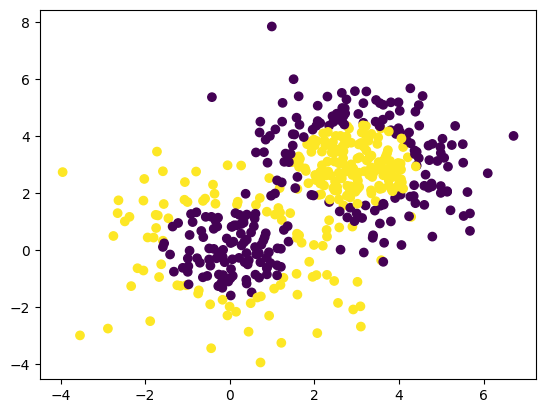

In [5]:
plt.scatter(df['X'],df['Y'],c=df['Class'])

In [7]:
X = df.iloc[:,0:2].values
y = df.iloc[:,-1].values

In [8]:
import tensorflow
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense
from tensorflow.keras.layers import BatchNormalization

In [9]:
model = Sequential()

model.add(Dense(2,activation='relu',input_dim=2))
model.add(Dense(2,activation='relu'))
model.add(Dense(1,activation='sigmoid'))

model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 2)                 6         
                                                                 
 dense_1 (Dense)             (None, 2)                 6         
                                                                 
 dense_2 (Dense)             (None, 1)                 3         
                                                                 
Total params: 15
Trainable params: 15
Non-trainable params: 0
_________________________________________________________________


In [10]:
model.compile(loss='binary_crossentropy',optimizer='adam',metrics=['accuracy'])

In [11]:
history1 = model.fit(X,y,epochs=200,validation_split=0.2)

Epoch 1/200
13/13 [==============================] - 2s 19ms/step - loss: 0.6868 - accuracy: 0.4637 - val_loss: 0.6960 - val_accuracy: 0.4600
Epoch 2/200
13/13 [==============================] - 0s 7ms/step - loss: 0.6860 - accuracy: 0.4561 - val_loss: 0.6955 - val_accuracy: 0.4700
Epoch 3/200
13/13 [==============================] - 0s 7ms/step - loss: 0.6854 - accuracy: 0.4612 - val_loss: 0.6953 - val_accuracy: 0.4700
Epoch 4/200
13/13 [==============================] - 0s 7ms/step - loss: 0.6849 - accuracy: 0.4612 - val_loss: 0.6949 - val_accuracy: 0.4700
Epoch 5/200
13/13 [==============================] - 0s 7ms/step - loss: 0.6844 - accuracy: 0.4712 - val_loss: 0.6947 - val_accuracy: 0.4700
Epoch 6/200
13/13 [==============================] - 0s 6ms/step - loss: 0.6840 - accuracy: 0.4787 - val_loss: 0.6945 - val_accuracy: 0.4900
Epoch 7/200
13/13 [==============================] - 0s 6ms/step - loss: 0.6836 - accuracy: 0.4737 - val_loss: 0.6943 - val_accuracy: 0.4900
Epoch 8/200


# Batch Normalization

In [12]:
model = Sequential()

model.add(Dense(3,activation='relu',input_dim=2))
model.add(BatchNormalization())
model.add(Dense(2,activation='relu'))
model.add(BatchNormalization())
model.add(Dense(1,activation='sigmoid'))

model.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_3 (Dense)             (None, 3)                 9         
                                                                 
 batch_normalization (BatchN  (None, 3)                12        
 ormalization)                                                   
                                                                 
 dense_4 (Dense)             (None, 2)                 8         
                                                                 
 batch_normalization_1 (Batc  (None, 2)                8         
 hNormalization)                                                 
                                                                 
 dense_5 (Dense)             (None, 1)                 3         
                                                                 
Total params: 40
Trainable params: 30
Non-trainable pa

In [13]:
model.compile(loss='binary_crossentropy',optimizer='adam',metrics=['accuracy'])

In [14]:
history2 = model.fit(X,y,epochs=200,validation_split=0.2)

Epoch 1/200
13/13 [==============================] - 1s 14ms/step - loss: 0.6973 - accuracy: 0.5388 - val_loss: 0.6922 - val_accuracy: 0.5600
Epoch 2/200
13/13 [==============================] - 0s 7ms/step - loss: 0.6908 - accuracy: 0.5263 - val_loss: 0.6922 - val_accuracy: 0.5500
Epoch 3/200
13/13 [==============================] - 0s 8ms/step - loss: 0.6902 - accuracy: 0.5489 - val_loss: 0.6919 - val_accuracy: 0.5500
Epoch 4/200
13/13 [==============================] - 0s 7ms/step - loss: 0.6919 - accuracy: 0.5489 - val_loss: 0.6913 - val_accuracy: 0.5600
Epoch 5/200
13/13 [==============================] - 0s 5ms/step - loss: 0.6912 - accuracy: 0.5288 - val_loss: 0.6905 - val_accuracy: 0.5500
Epoch 6/200
13/13 [==============================] - 0s 6ms/step - loss: 0.6879 - accuracy: 0.5313 - val_loss: 0.6898 - val_accuracy: 0.5700
Epoch 7/200
13/13 [==============================] - 0s 5ms/step - loss: 0.6859 - accuracy: 0.5414 - val_loss: 0.6890 - val_accuracy: 0.5700
Epoch 8/200


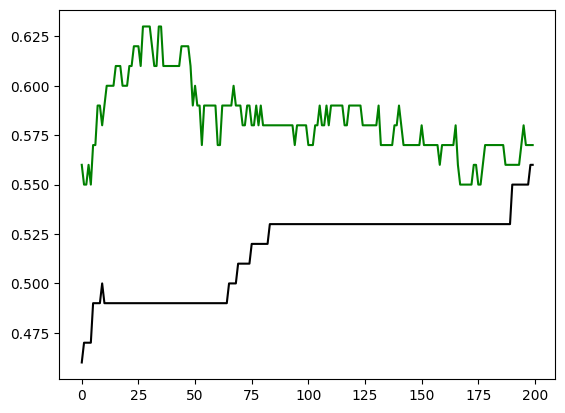

In [15]:
plt.plot(history1.history['val_accuracy'],color='black')
plt.plot(history2.history['val_accuracy'],color='green')